In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("Data/AIML Dataset.csv")

In [4]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [6]:
df.shape

(6362620, 11)

In [7]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [8]:
df.isnull().sum().sum()

np.int64(0)

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df["isFraud"].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [11]:
y_values_distribution = round((df["isFraud"].value_counts() / df.shape[0]) * 100, 2)
y_values_distribution

isFraud
0    99.87
1     0.13
Name: count, dtype: float64

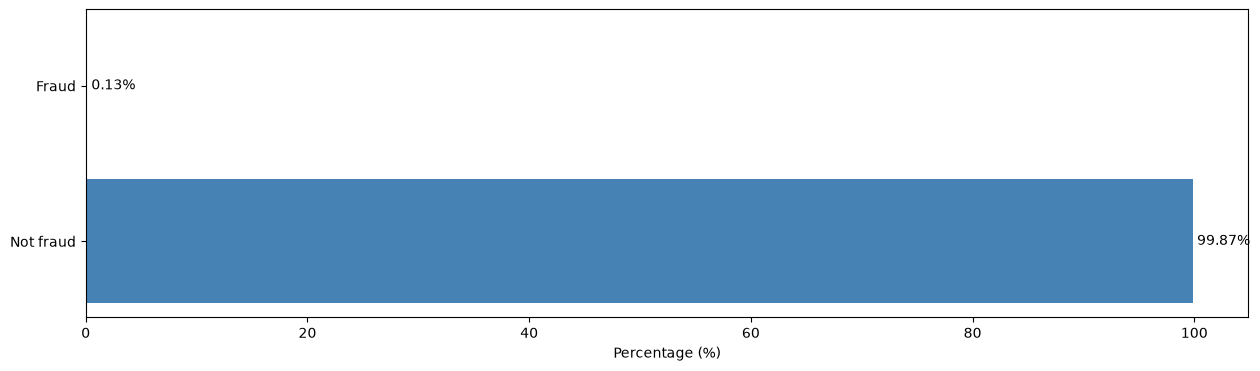

In [12]:
plt.figure(figsize=(15, 4))
bars = plt.barh(['Not fraud', 'Fraud'], y_values_distribution.values, color=['steelblue', 'crimson'])
plt.bar_label(bars, fmt='%.2f%%', padding=3)
plt.xlabel('Percentage (%)')
plt.show()

In [13]:
df.describe().drop(["count"]).astype(int)

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
mean,243,179861,833883,855113,1100701,1224996,0,0
std,142,603858,2888242,2924048,3399180,3674128,0,0
min,1,0,0,0,0,0,0,0
25%,156,13389,0,0,0,0,0,0
50%,239,74871,14208,0,132705,214661,0,0
75%,335,208721,107315,144258,943036,1111909,0,0
max,743,92445516,59585040,49585040,356015889,356179278,1,1


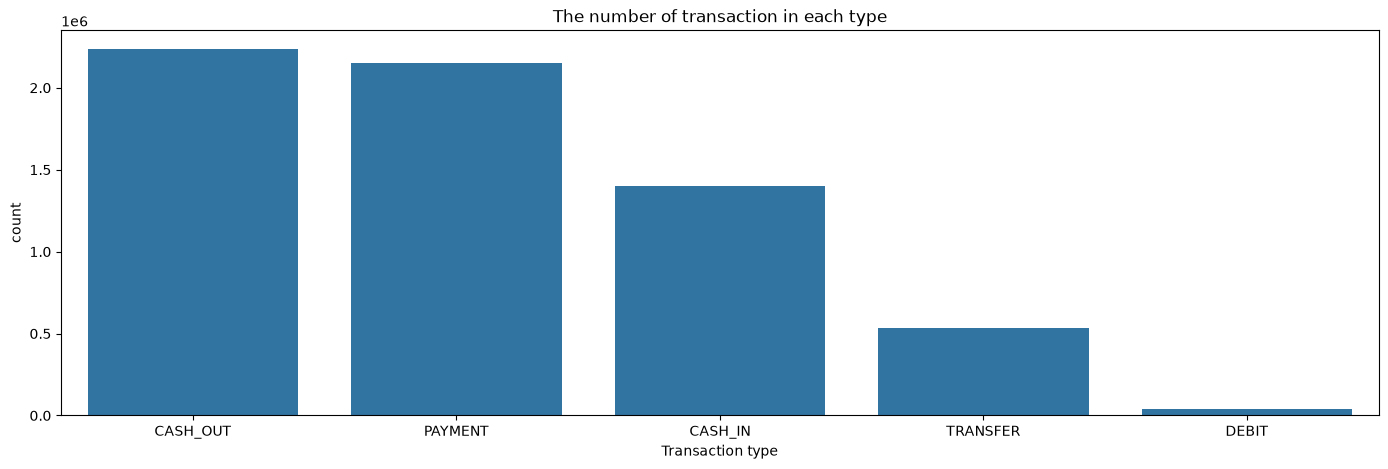

In [14]:
plt.figure(figsize=(17,5))
sns.barplot(df["type"].value_counts())
plt.title("The number of transaction in each type")
plt.xlabel("Transaction type")
plt.ylabel("count")
plt.show()

In [15]:
fraud_by_type = df.groupby("type")["isFraud"].value_counts().sort_values(ascending=False)
fraud_by_type

type      isFraud
CASH_OUT  0          2233384
PAYMENT   0          2151495
CASH_IN   0          1399284
TRANSFER  0           528812
DEBIT     0            41432
CASH_OUT  1             4116
TRANSFER  1             4097
Name: count, dtype: int64

In [16]:
fraud_by_type / df.shape[0]

type      isFraud
CASH_OUT  0          0.351016
PAYMENT   0          0.338146
CASH_IN   0          0.219923
TRANSFER  0          0.083112
DEBIT     0          0.006512
CASH_OUT  1          0.000647
TRANSFER  1          0.000644
Name: count, dtype: float64

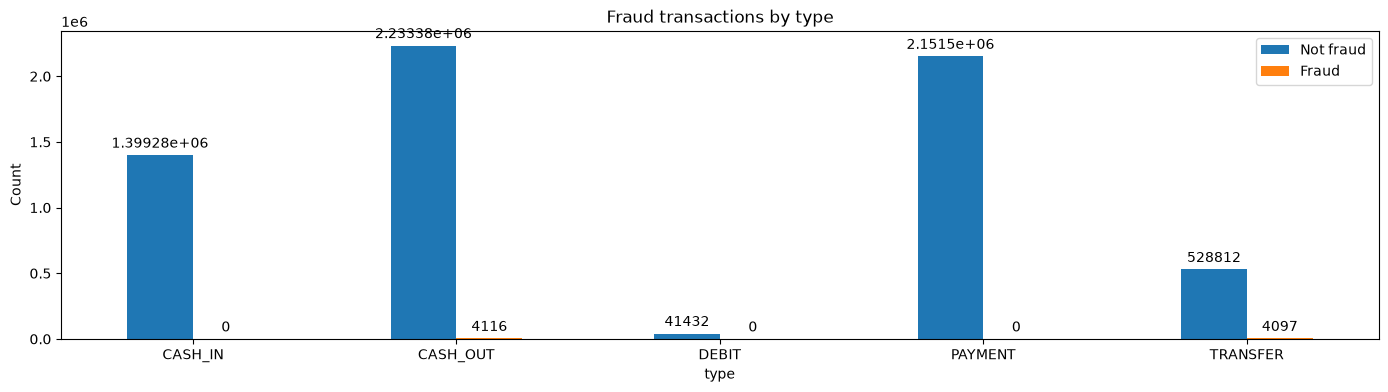

In [17]:
ax = fraud_by_type.unstack(fill_value=0).plot(kind="bar", figsize=(17, 4), title="Fraud transactions by type")
for c in ax.containers:
    ax.bar_label(c, padding=3)
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.legend(["Not fraud", "Fraud"])
plt.show()

In [18]:
fraud_types = df[df["isFraud"] == 1]["type"].value_counts()
fraud_types 

type
CASH_OUT    4116
TRANSFER    4097
Name: count, dtype: int64

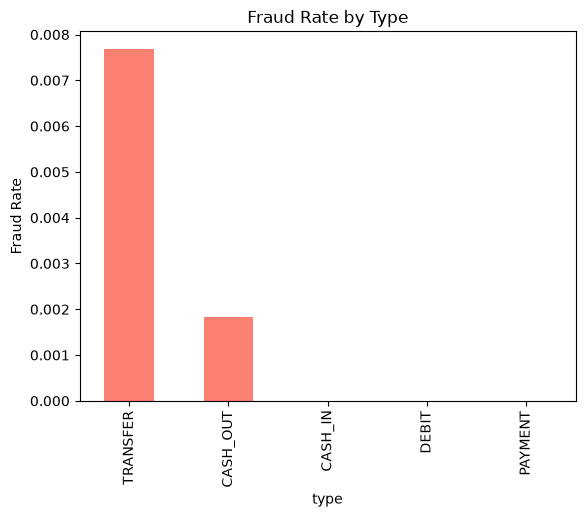

In [19]:
fraud_rate = df.groupby("type")["isFraud"].mean().sort_values(ascending=False)
fraud_rate.plot(kind="bar", title="Fraud Rate by Type", color="salmon")
plt.ylabel("Fraud Rate")
plt.show()

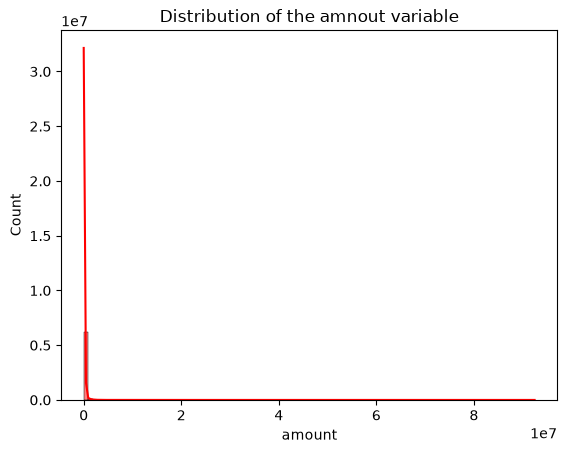

In [20]:
sns.histplot(df["amount"], bins=100, kde=True, color="red")
plt.title("Distribution of the amnout variable")
plt.show()

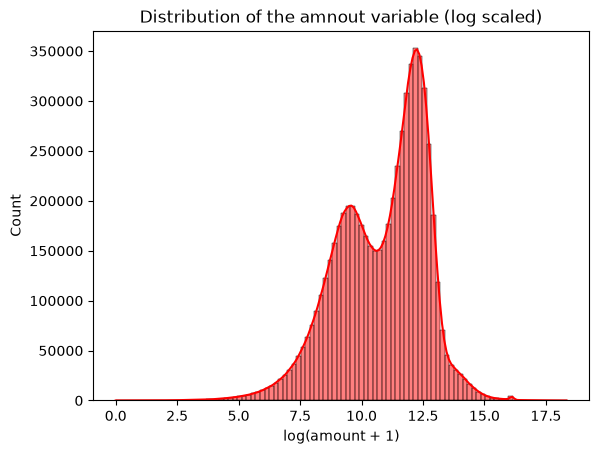

In [21]:
sns.histplot(np.log1p(df["amount"]), bins=100, kde=True, color="red")
plt.xlabel("log(amount + 1)")
plt.title("Distribution of the amnout variable (log scaled)")
plt.show()

In [22]:
numerics = ['int16', 'int32', 'int64', 'float16', 'float32', 'float64']
newdf = df.select_dtypes(include=numerics)

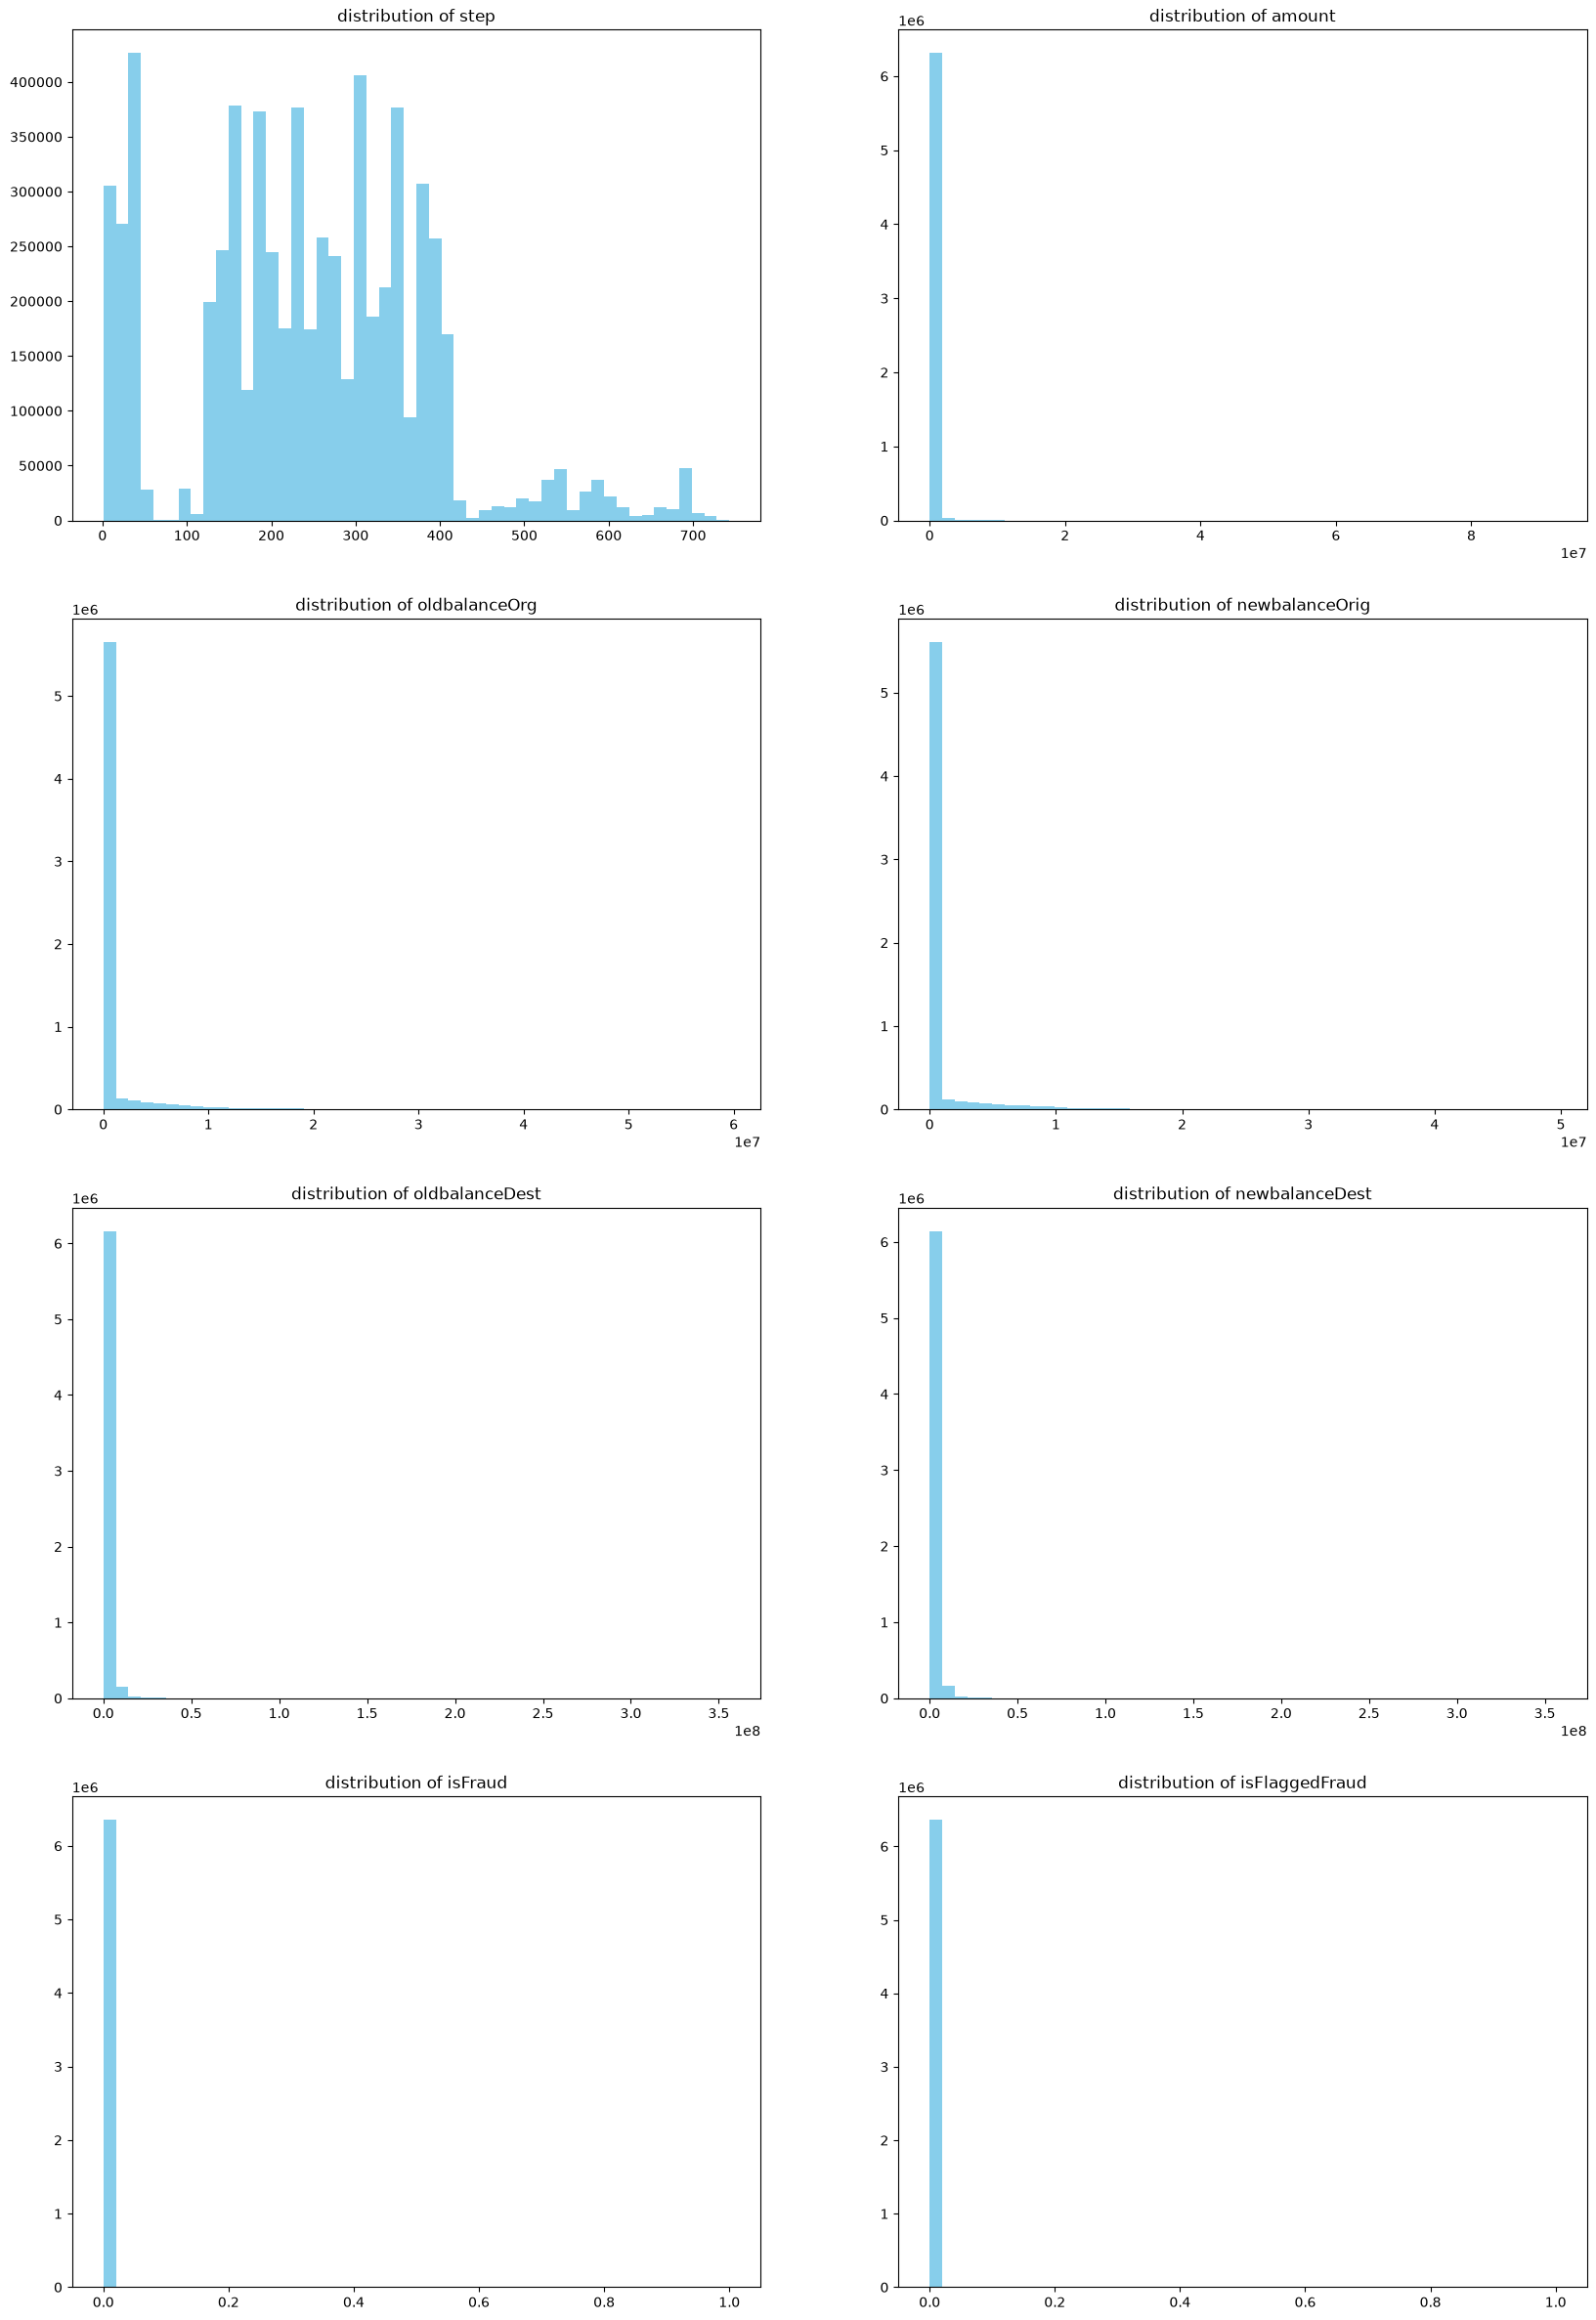

In [23]:
plt.figure(figsize=(20,30))
i=1
for column in newdf.columns:
    plt.subplot(4,2,i)
    plt.hist(newdf[column], bins=50, color="skyblue")
    plt.title("distribution of "+ column)
    i+=1
plt.show()

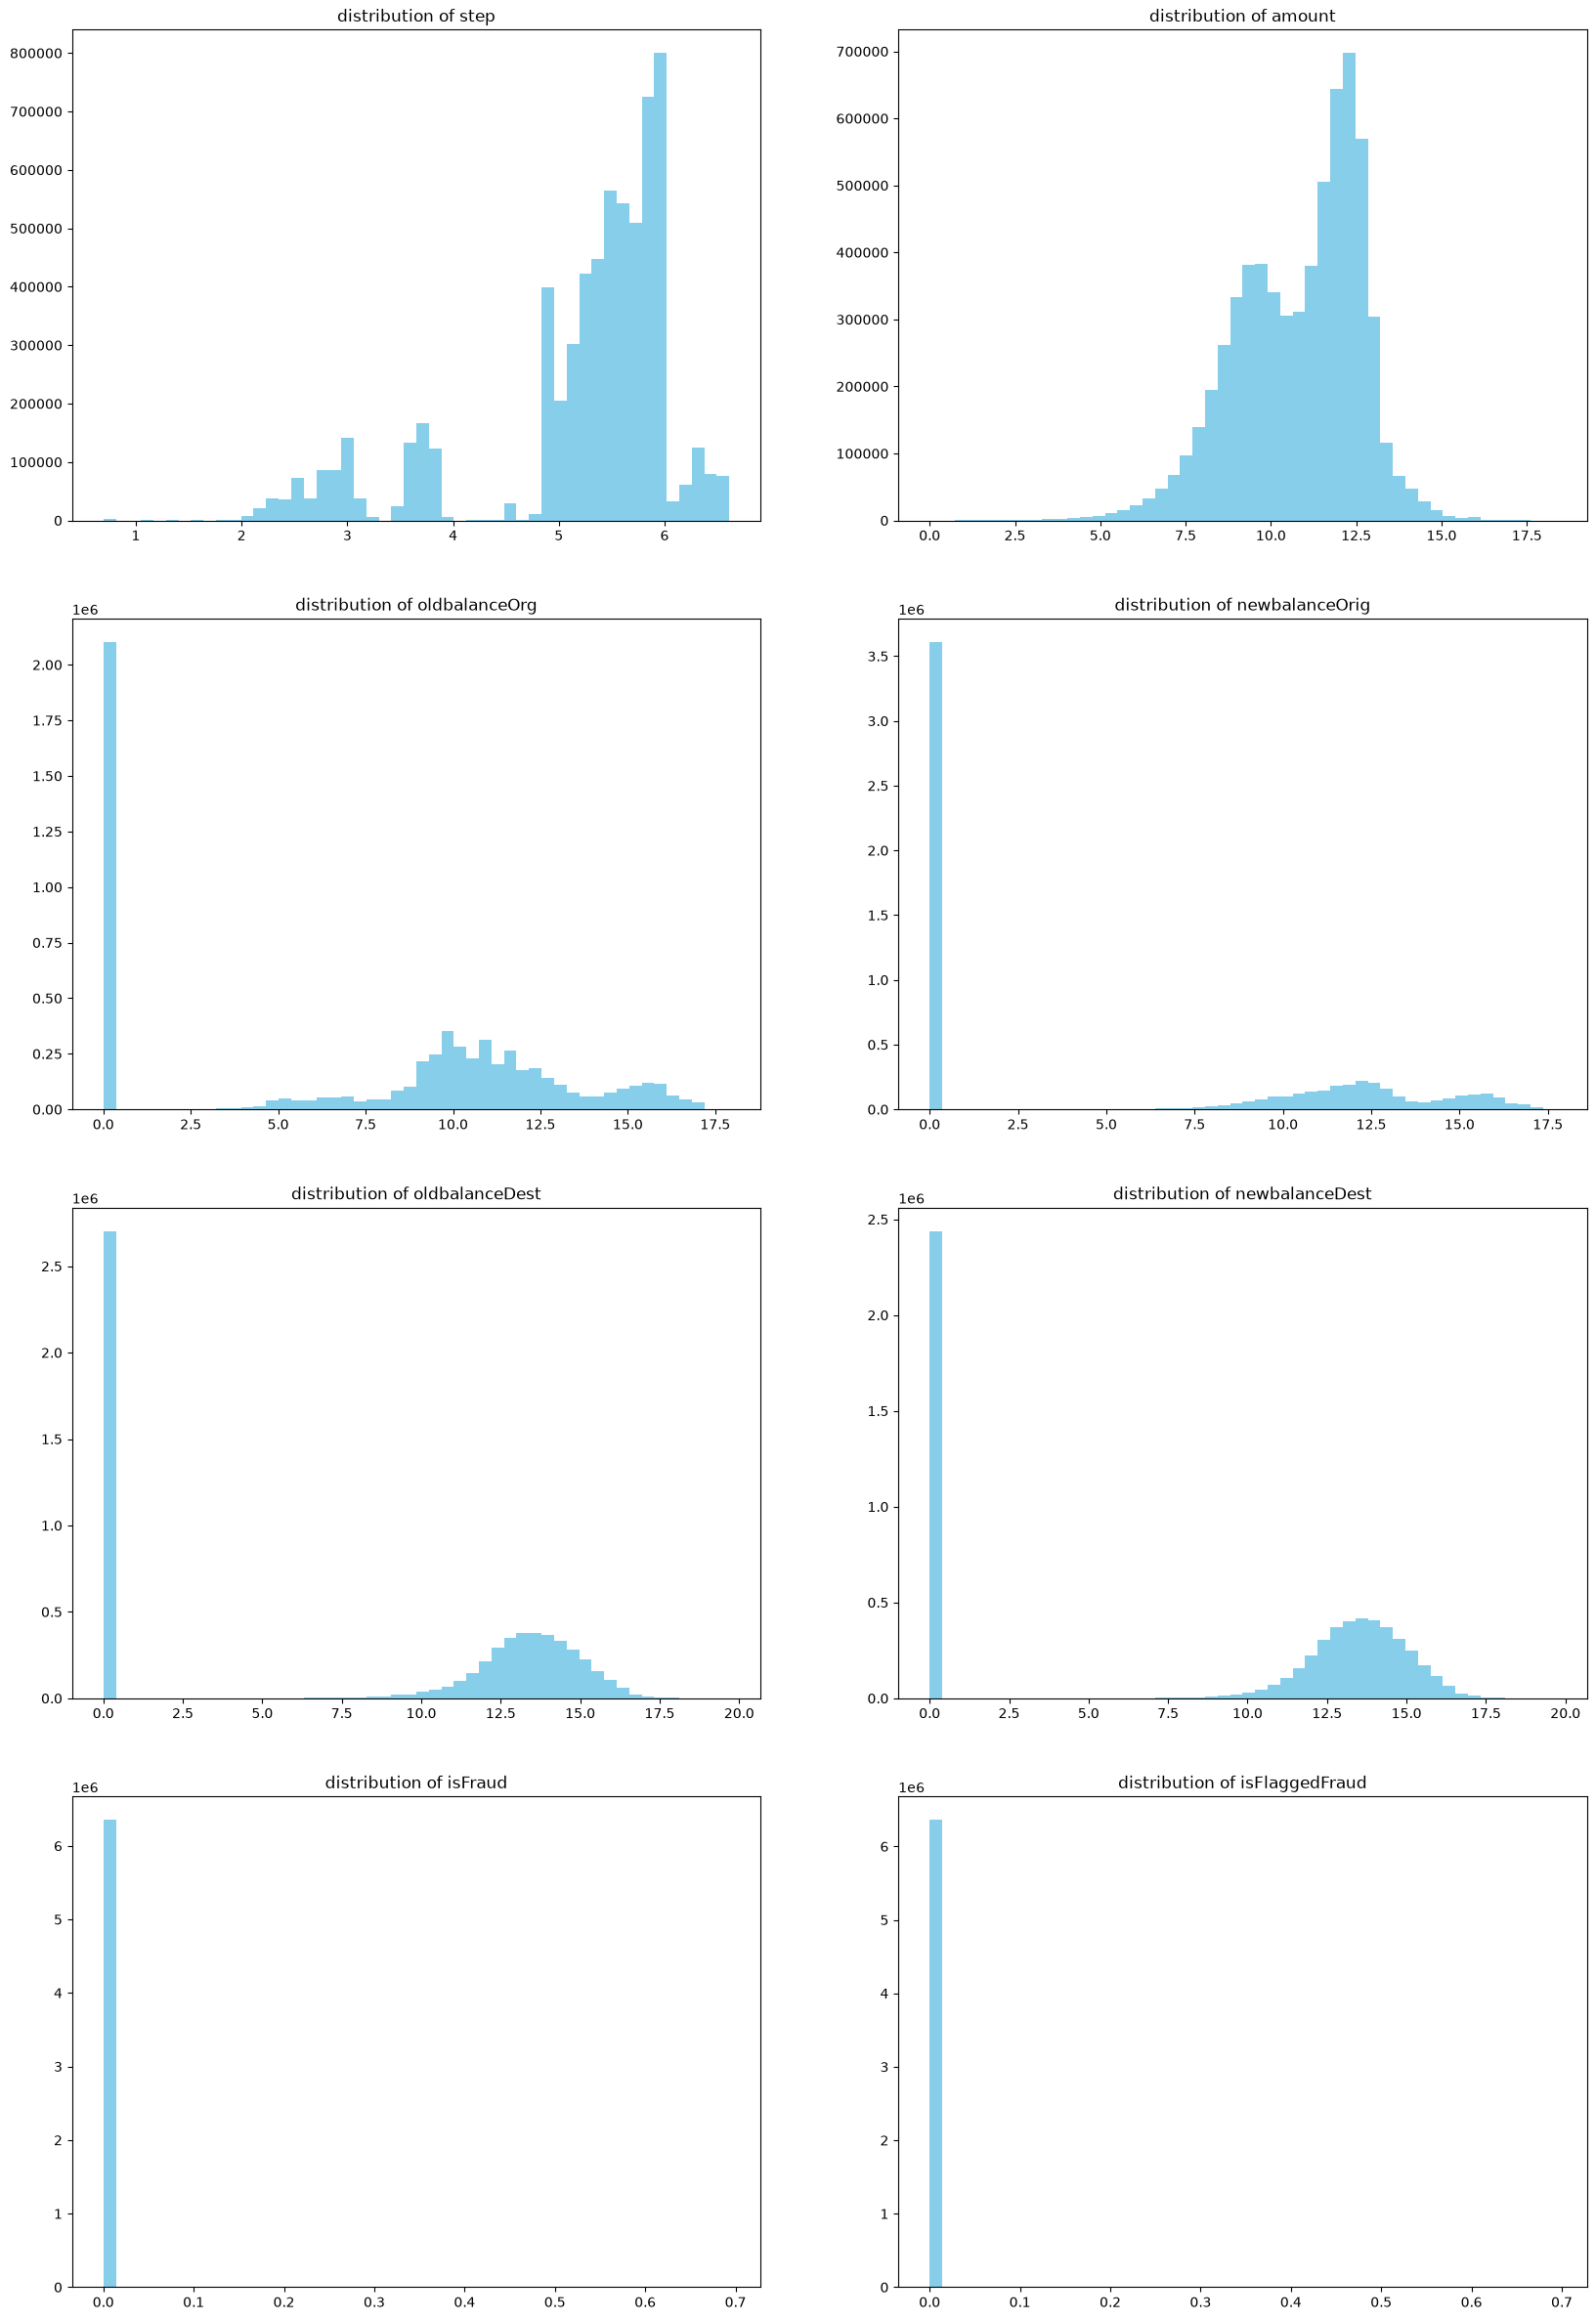

In [24]:
plt.figure(figsize=(20,30))
i=1
for column in newdf.columns:
    plt.subplot(4,2,i)
    plt.hist(np.log1p(newdf[column]), bins=50, color="skyblue")
    plt.title("distribution of "+ column)
    i+=1
plt.show()

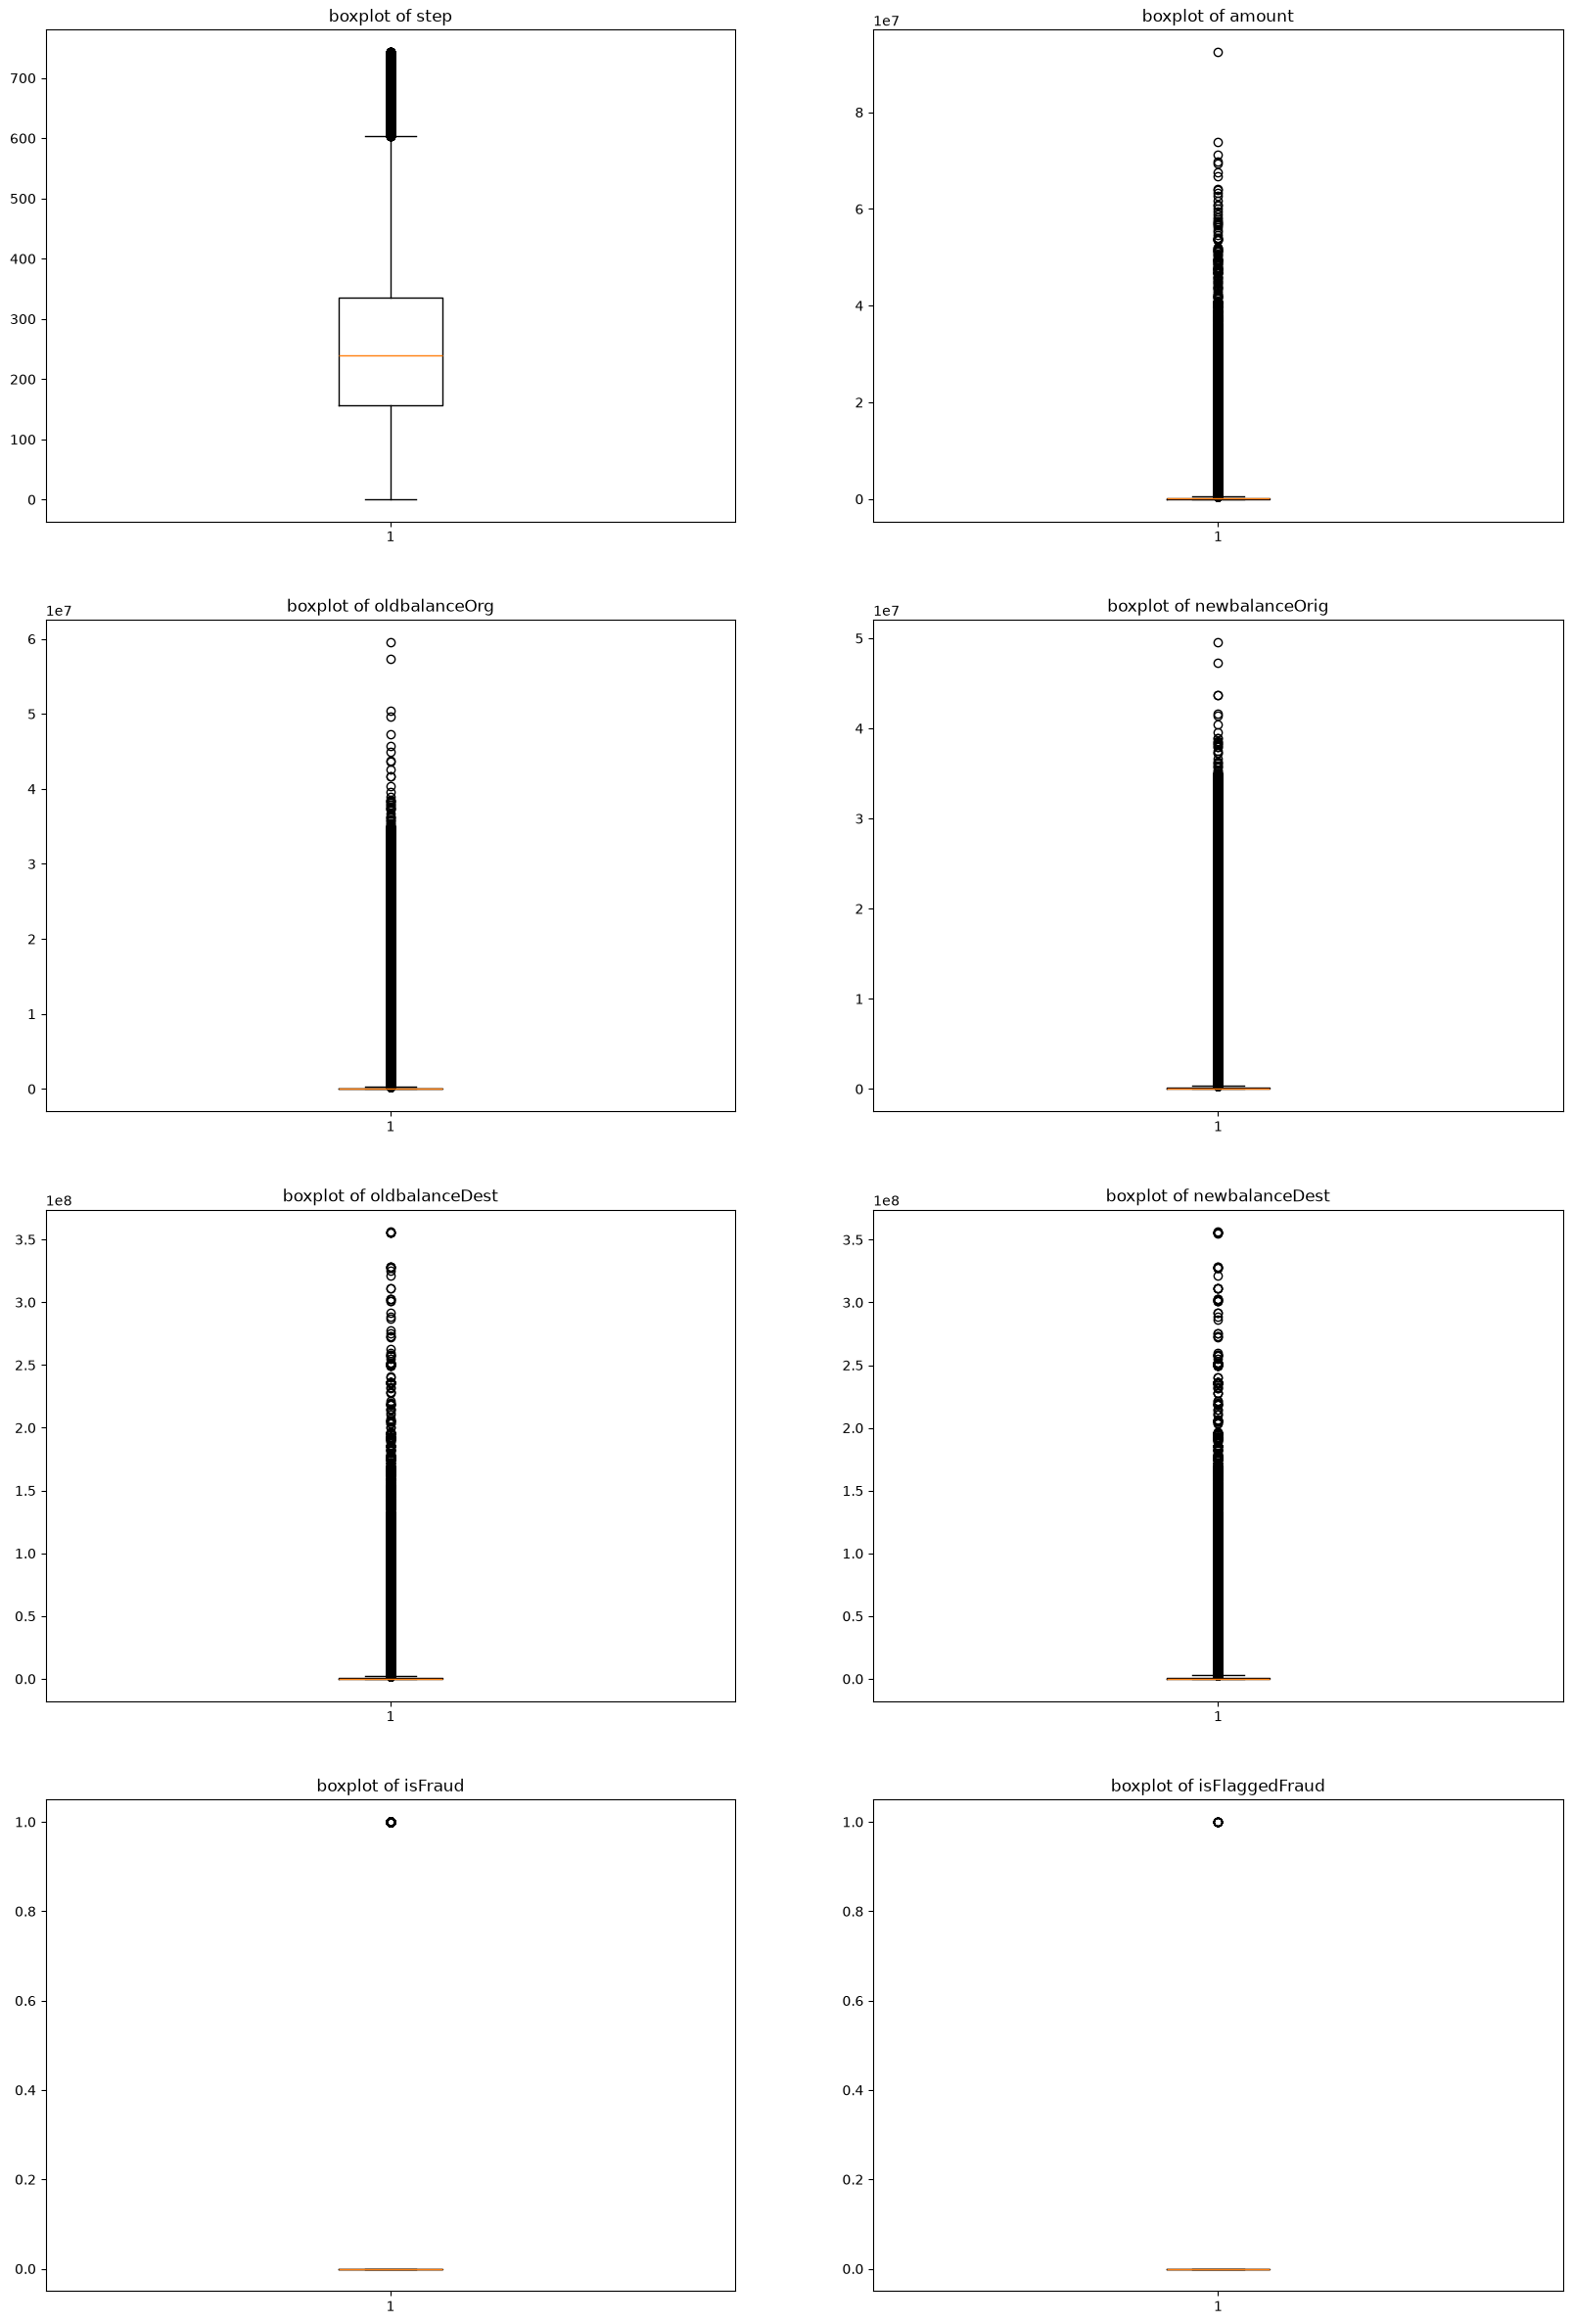

In [25]:
plt.figure(figsize=(20,30))
i=1
for column in newdf.columns:
    plt.subplot(4,2,i)
    plt.boxplot(newdf[column], )
    plt.title("boxplot of "+ column)
    i+=1
plt.show()

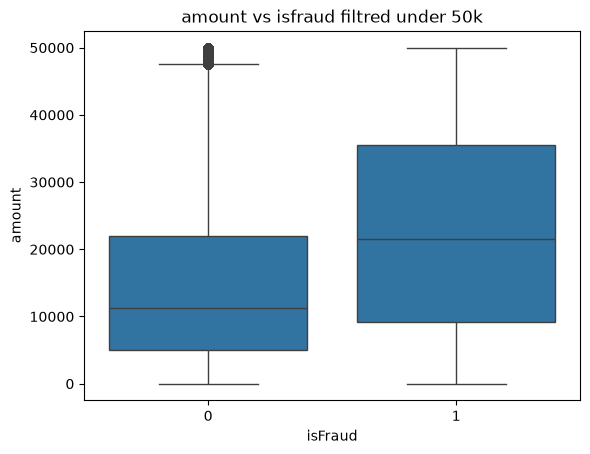

In [26]:
sns.boxplot(df[df["amount"]< 50000], x="isFraud", y="amount")
plt.title("amount vs isfraud filtred under 50k")
plt.show()

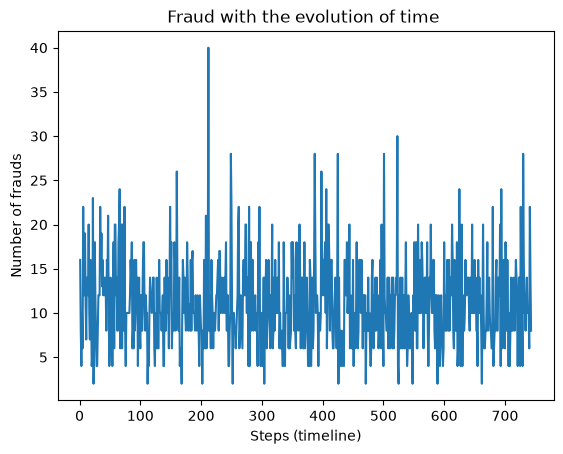

In [27]:
fraud_per_step = df[df["isFraud"] == 1]["step"].value_counts().sort_index()
plt.plot(fraud_per_step)
plt.xlabel("Steps (timeline)")
plt.ylabel("Number of frauds")
plt.title("Fraud with the evolution of time ")
plt.show()

In [28]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='str')

In [29]:
top_senders = df["nameOrig"].value_counts().head(10)
top_senders

nameOrig
C2098525306    3
C400299098     3
C1999539787    3
C1065307291    3
C545315117     3
C1976208114    3
C1784010646    3
C1530544995    3
C1902386530    3
C1677795071    3
Name: count, dtype: int64

In [30]:
top_recivers = df["nameDest"].value_counts().head(10)
top_recivers

nameDest
C1286084959    113
C985934102     109
C665576141     105
C2083562754    102
C248609774     101
C1590550415    101
C451111351      99
C1789550256     99
C1360767589     98
C1023714065     97
Name: count, dtype: int64

In [31]:
fraud_users = df[df["isFraud"] == 1]["nameOrig"].value_counts().head(10)
fraud_users

nameOrig
C1305486145    1
C840083671     1
C1420196421    1
C2101527076    1
C137533655     1
C1118430673    1
C749981943     1
C1334405552    1
C467632528     1
C1364127192    1
Name: count, dtype: int64

In [32]:
fraud_in_types = df[df["type"].isin(["TRANSFER", "CASH_OUT"])]
fraud_in_types["type"].value_counts()

type
CASH_OUT    2237500
TRANSFER     532909
Name: count, dtype: int64

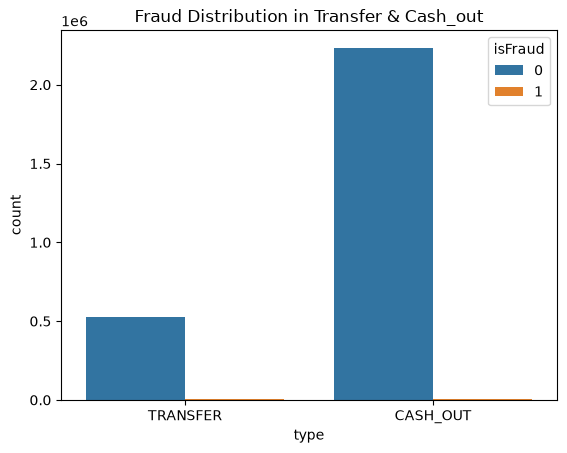

In [33]:
sns.countplot(data=fraud_in_types, x="type", hue="isFraud")
plt.title("Fraud Distribution in Transfer & Cash_out")
plt.show()

In [34]:
corr = df[newdf.columns].corr()
corr

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
step,1.000000,0.022373,-0.010058,-0.010299,0.027665,0.025888,0.031578,0.003277
amount,0.022373,1.000000,-0.002762,-0.007861,0.294137,0.459304,0.076688,0.012295
oldbalanceOrg,-0.010058,-0.002762,1.000000,0.998803,0.066243,0.042029,0.010154,0.003835
newbalanceOrig,-0.010299,-0.007861,0.998803,1.000000,0.067812,0.041837,-0.008148,0.003776
oldbalanceDest,0.027665,0.294137,0.066243,0.067812,1.000000,0.976569,-0.005885,-0.000513
newbalanceDest,0.025888,0.459304,0.042029,0.041837,0.976569,1.000000,0.000535,-0.000529
isFraud,0.031578,0.076688,0.010154,-0.008148,-0.005885,0.000535,1.000000,0.044109
isFlaggedFraud,0.003277,0.012295,0.003835,0.003776,-0.000513,-0.000529,0.044109,1.000000


In [35]:
corr_sorted= df.corr(numeric_only=True)["isFraud"].sort_values(ascending=False)

corr_sorted

isFraud           1.000000
amount            0.076688
isFlaggedFraud    0.044109
step              0.031578
oldbalanceOrg     0.010154
newbalanceDest    0.000535
oldbalanceDest   -0.005885
newbalanceOrig   -0.008148
Name: isFraud, dtype: float64

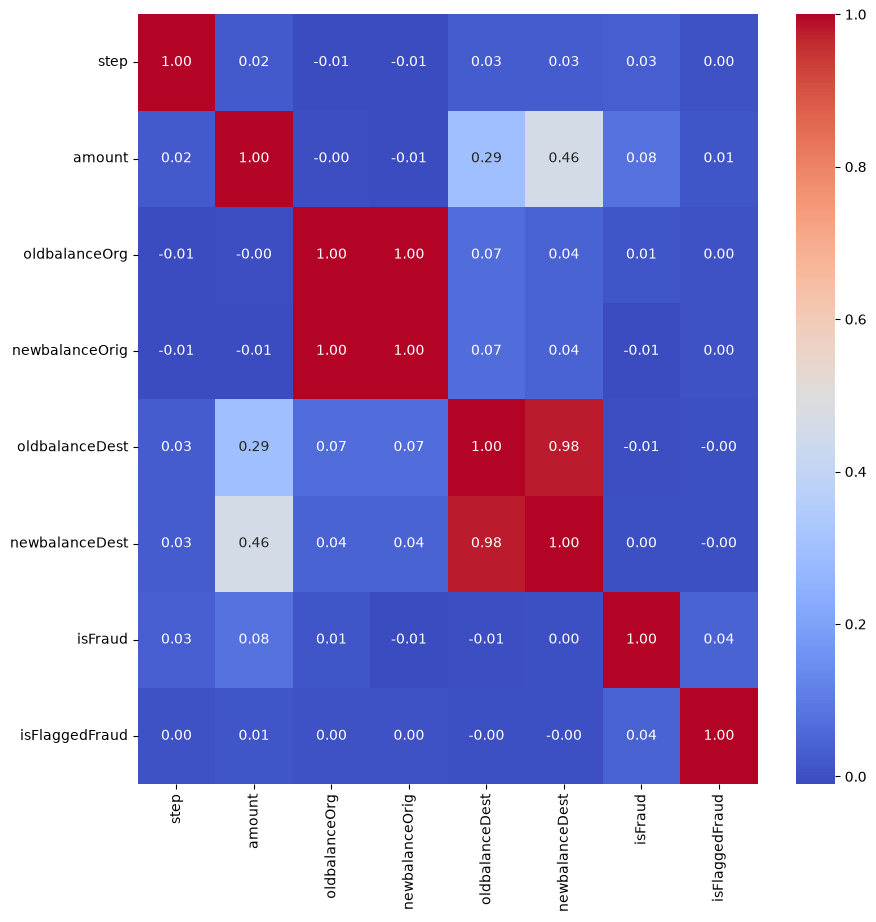

In [36]:
plt.figure(figsize=(10,10))
sns.heatmap(corr, annot=True,cmap="coolwarm", fmt=".2f")
plt.show()

In [37]:
zero_after_transfer = df[(df["oldbalanceOrg"] > 0 )&
                          (df["newbalanceOrig"] == 0) &
                          (df["type"].isin(["TRANSFER", "CASH_OUT"]))
                          ]
len(zero_after_transfer)

1188074

In [38]:
zero_after_transfer.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
2,1,TRANSFER,181.00,C1305486145,181.0,0.0,C553264065,0.0,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.0,C38997010,21182.0,0.00,1,0
15,1,CASH_OUT,229133.94,C905080434,15325.0,0.0,C476402209,5083.0,51513.44,0,0
19,1,TRANSFER,215310.30,C1670993182,705.0,0.0,C1100439041,22425.0,0.00,0,0
24,1,TRANSFER,311685.89,C1984094095,10835.0,0.0,C932583850,6267.0,2719172.89,0,0


In [39]:
Dest_after_transfer = df[(df["oldbalanceDest"] == 0 )&
                          (df["newbalanceDest"] > 0) &
                          (df["type"].isin(["TRANSFER", "CASH_OUT"]))
                          ]
len(Dest_after_transfer)

383538

In [40]:
Dest_after_transfer.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
811,1,TRANSFER,84212.94,C1336775847,53199.00,0.00,C13329486,0.0,84212.94,0,0
830,1,TRANSFER,621561.65,C82275756,123122.00,0.00,C1782113663,0.0,3997768.55,0,0
970,1,CASH_OUT,1277212.77,C467632528,1277212.77,0.00,C716083600,0.0,2444985.19,1,0
1169,1,CASH_OUT,9980.32,C1589466857,12936.00,2955.68,C1018298342,0.0,9980.32,0,0
1404,1,TRANSFER,490341.11,C242408359,20846.00,0.00,C1504109395,0.0,593737.38,0,0


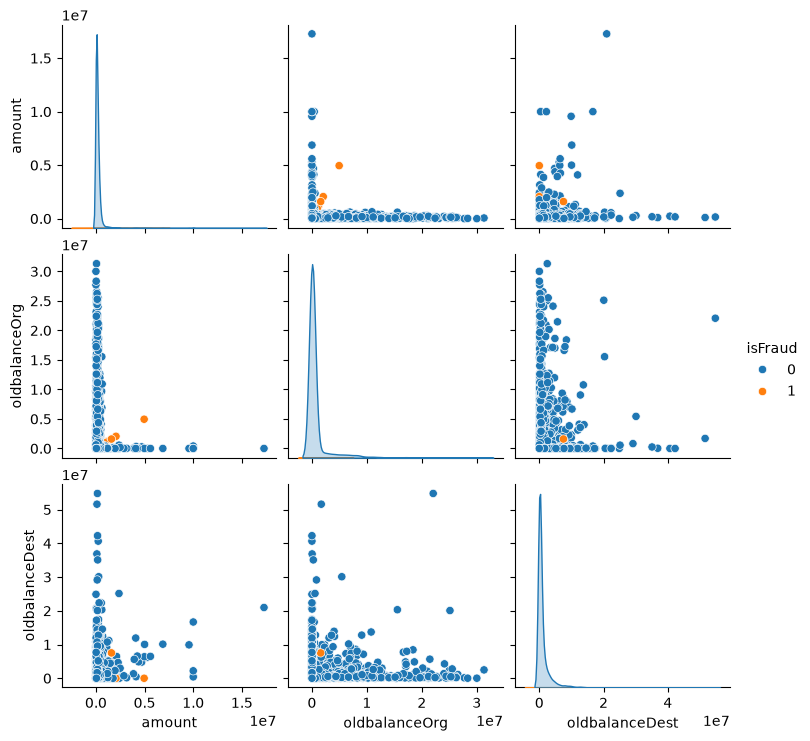

In [42]:
sample = df.sample(5000, random_state=42)

sns.pairplot(
    sample[columns + ["isFraud"]],
    hue="isFraud",
    diag_kind="kde"
)

plt.show()

